<div dir="rtl">

# مقارنة تجريبية لأربع تقنيات في كشف رسائل الاحتيال

</div>


<div dir="rtl">

## المشكلة

في 3 مايو 1978 أرسل موظف تسويق في شركة DEC رسالة إعلانية واحدة إلى نحو 400 مستخدم على شبكة ARPANET، التي سبقت الإنترنت، وتُعدّ اليوم أول رسالة سبام في التاريخ [1]. ومنذ ذلك الحين تحولت الرسائل غير المرغوب فيها من إعلانات مزعجة إلى أداة احتيال: جوائز وهمية، وتحذيرات من إيقاف الحساب، وطلبات لرمز التحقق. وانتقلت هذه الرسائل من البريد الإلكتروني إلى الرسائل النصية وتطبيقات المحادثة.

تُسمّى الرسالة غير المرغوب فيها أو الاحتيالية **سبام (spam)**، وتُسمّى الرسالة العادية **هام (ham)**. ومهمة الكشف مسألة **تصنيف (Classification)**: إسناد كل رسالة إلى إحدى هاتين الفئتين.

ولكن هناك تحدٍّ أكبر يجعل قائمة الكلمات المشبوهة وحدها غير كافية لتصفية الرسائل المزعجة، لثلاثة أسباب [60]:

**أولًا، تغيّر أسلوب المحتال.** في معظم مسائل التصنيف تبقى البيانات على حالها بعد تشغيل النظام. أما في كشف الاحتيال فيراقب المحتال الرسائل المحجوبة ثم يعدّل الأسلوب: كتابة "ر.ب.ح.ت" بدل "ربحت"، أو حذف الرابط، أو تقليد رسالة البنك بإتقان. ولهذا يسمّي الباحثون هذه المسألة **التصنيف العدائي (Adversarial Classification)**، فأداء النظام يتراجع بعد التشغيل كلما وجد المحتالون طرقًا لتجاوز التصنيف [61][5].

**ثانيًا، تفاوت الأخطاء في الضرر.** وصول رسالة احتيال إلى صندوق الوارد قد ينتهي بتعرّف المستخدم على الرسالة وحذفها. أما حجب رسالة حقيقية، كموعد مقابلة عمل أو تنبيه من البنك، فقد يحول دون علم المستخدم بوصول الرسالة. لذلك تتعامل المرشّحات مع "الإنذار الكاذب" بحذر أكبر من "الرسالة الفائتة"، وعلى هذه الفكرة بُني أول مرشّح احتمالي للبريد المزعج [2].

**ثالثًا، تغيّر محتوى الرسائل.** لا تثبت نسبة الرسائل المزعجة ولا موضوعات هذه الرسائل: اليوم جوائز وهمية، وغدًا شحنات متأخرة ومخالفات مرورية. ولذلك يتراجع أداء النظام المدرَّب على رسائل قديمة حين تظهر موضوعات وأساليب جديدة [60]. وتزداد الصعوبة في العربية، فالرسالة الواحدة قد تُكتب بالفصحى أو بالعامية أو بالإنجليزية، وكلمة مثل "مبروك" قد تأتي في تهنئة صادقة كما تأتي في رسالة احتيال.

</div>


<div dir="rtl">

## التقنيات

مرّ كشف رسائل الاحتيال بأربع تقنيات أساسية حتى وصل إلى ما هو عليه اليوم. أولى هذه التقنيات البرمجة التقليدية، حيث يكتب المبرمج قواعد ثابتة تحدد الرسالة المشبوهة. ثم جاء تعلّم الآلة بحيث يتعلم النموذج وزن كل كلمة من رسائل مصنّفة مسبقًا. وبعد ذلك ظهر التعلّم العميق الذي يعالج الجملة كاملة مع مراعاة السياق. وآخر هذه التقنيات النماذج اللغوية الكبيرة، والتي تصنّف الرسالة من وصف المهمة دون تدريب على بيانات خاصة. وظهرت كل تقنية لمعالجة قصور في التقنية السابقة، دون أن تحل محل تلك التقنية بالكامل في الأنظمة الكبرى، كما في Gmail وMicrosoft (التفاصيل في القسم 10.3) [63][37]. وفي المقابل غيّر المحتالون أساليب كتابة الرسائل استجابةً للمرشّحات: تراجعت بعض الأساليب بعد كشف المرشّحات لتلك الأساليب، واستمرت أساليب أخرى [62].

<img src="assets/ai_umbrella.svg" width="700">

يقع الإطار المنقّط (البرمجة التقليدية) خارج دائرة الذكاء الاصطناعي، وتقع كل تقنية لاحقة داخل التقنية السابقة. ويشير Symbolic AI إلى فرع من الذكاء الاصطناعي يستنتج القرار من قاعدة معرفة، وهو خارج نطاق هذه التجربة.

وفيما يلي تفصيل كل تقنية: المشكلة المعالَجة، وآلية العمل، والمزايا، والمشكلات.

</div>


<div dir="rtl">

### التقنية الأولى: البرمجة التقليدية (Traditional Programming)
- **آلية العمل:** كتابة المبرمج للمنطق يدويًا، ثم تطبيق البرنامج لهذا المنطق على البيانات لإخراج الإجابة: **قواعد + بيانات ← إجابات**. وفي كشف الاحتيال يعني ذلك إعداد الخبير قائمة بالكلمات والأنماط المشبوهة، مع منح كل نمط عددًا من النقاط. وعند تجاوز مجموع النقاط حدًّا معينًا، تُصنَّف الرسالة احتيالًا. وعلى هذا الأساس يعمل SpamAssassin، أحد أشهر مرشّحات البريد، والمستخدم حتى اليوم [3].
- **المزايا:** السرعة والوضوح، وإمكانية تفسير كل قرار.
- **المشكلات:** غياب التعلّم؛ فكل أسلوب احتيال جديد يتطلب قاعدة جديدة يكتبها إنسان، وتغيير حرف واحد يكفي لتجاوز القاعدة. ويضاف إلى ذلك غياب مراعاة السياق، فكلمة "مبروك" تُعدّ مؤشرًا مشبوهًا أينما وردت. وهذا ما يصفه الفصل الأول من كتاب Géron، الذي يتخذ مرشّح البريد المزعج مثالًا افتتاحيًا: تتحول البرمجة التقليدية مع الوقت إلى "قائمة طويلة من القواعد المعقدة" صعبة الصيانة [51].

### التقنية الثانية: تعلّم الآلة (Naive Bayes)
- **المشكلة التي عالجتها:** كتابة المنطق يدويًا.
- **آلية العمل:** عكس الاتجاه السابق: تزويد النموذج بالرسائل مع التصنيف الصحيح، ثم استخراج النموذج للقواعد والأوزان: **بيانات + إجابات ← قواعد**. وهي مقارنة شهيرة يعرضها الفصل الأول من كتاب Chollet [59]. وتُسمّى الكلمات المعتمدة في القرار **الخصائص (Features)**، ويحدّد الإنسان هذه الخصائص في هذه التقنية، ثم تُحوَّل إلى أرقام بأسلوب يُسمّى **TF-IDF**. ويضيف Géron أن النموذج المتعلّم يتكيّف تلقائيًا مع تغيير المحتالين للكلمات، ككتابة "For U" بدل "4U"، بإعادة التدريب على الرسائل الجديدة دون كتابة قاعدة جديدة [51]. وقد اقترح Sahami وآخرون عام 1998 مرشّحًا احتماليًا من هذا النوع [2]، ثم انتشرت هذه التقنية بعد مقال Paul Graham الشهير "A Plan for Spam" عام 2002 [4].
- **المزايا:** اكتشاف كلمات مؤثرة خارج ما يحدده الإنسان، والتحديث بإعادة التدريب على بيانات جديدة.
- **المشكلات:** الحاجة إلى بيانات مصنّفة، ومعاملة الرسالة على أنها مجموعة كلمات منفصلة بلا ترتيب ولا سياق. ولهذا يمكن تجاوز التصنيف بحشو الرسالة بكلمات عادية، فيما يُعرف بهجوم الكلمات الجيدة (Good Word Attack) [5].

### التقنية الثالثة: التعلّم العميق (Transformer)
- **المشكلة التي عالجتها:** غياب مراعاة السياق.
- **آلية العمل:** معالجة الجملة كاملة عبر آلية الانتباه الذاتي (Self-Attention)، أي تحديد أهمية كل كلمة بالنسبة إلى بقية الكلمات، في بنية Transformer التي ظهرت عام 2017 [6]. وتُدرَّب نماذج مثل BERT مسبقًا على نصوص ضخمة (Pre-training)، ثم تُضبط على مهمة محددة بقليل من البيانات (Fine-tuning) [7].
- **المزايا:** تمثيل المعنى، ومقاومة أفضل للتمويه، والاستغناء عن تحديد الإنسان للخصائص.
- **المشكلات:** الحاجة إلى قدرة حوسبة أكبر وإلى بيانات مصنّفة، وصعوبة أكبر في تفسير القرارات.

### التقنية الرابعة: النماذج اللغوية الكبيرة دون تدريب (LLM Zero-shot)
- **المشكلة التي عالجتها:** الحاجة إلى بيانات مصنّفة.
- **آلية العمل:** أداء نموذج عام لمهمة جديدة اعتمادًا على وصف المهمة بالكلام فقط، كما أظهرت نماذج مثل GPT-3 عام 2020 [9].
- **المزايا:** التعامل مع أساليب غائبة عن بيانات التجربة، وتقديم شرح للقرار بلغة مفهومة.
- **المشكلات:** بطء أكبر وتكلفة أعلى لكل رسالة، ولذلك لا تصلح هذه النماذج منفردةً لفحص ملايين الرسائل يوميًا، فضلًا عن احتمال تغيّر الجواب بتغيّر صياغة الطلب. كما أن الشرح المقدَّم لا يعكس بالضرورة ما يجري داخل النموذج [10].

</div>


<div dir="rtl">

### ملخص التقنيات

| التقنية | الإضافة | المشكلات |
|---|---|---|
| 1. البرمجة التقليدية (Traditional Programming) | أتمتة الفرز بقواعد واضحة قابلة للتفسير | غياب التعلّم، وإمكانية التجاوز بتغيير حرف واحد |
| 2. تعلّم الآلة: Naive Bayes + TF-IDF | تعلّم الأوزان من البيانات بدل الكتابة اليدوية | غياب مراعاة السياق، والتأثر بحشو الرسالة بكلمات عادية |
| 3. التعلّم العميق: Transformer | مراعاة السياق ومقاومة التمويه | حوسبة أكبر وتفسير أصعب |
| 4. نموذج لغوي كبير (LLM Zero-shot) | الاستغناء عن البيانات المصنّفة | تكلفة وبطء، وشرح قد لا يعكس ما يجري داخل النموذج |

</div>


<div dir="rtl">

## أهداف التجربة

تهدف هذه التجربة إلى:
1. التمييز بين البرمجة التقليدية (قواعد يكتبها الإنسان) والذكاء الاصطناعي (نماذج تتعلّم من البيانات)، وبين تعلّم الآلة والتعلّم العميق والنماذج اللغوية الكبيرة.
2. التعرّف على المشكلة التي عالجتها كل تقنية، والقصور الباقي بعد المعالجة، وتكلفة البيانات والحوسبة.
3. المقارنة بين أداء التقنيات الأربع على رسائل مشابهة لبيانات التدريب وعلى رسائل بأساليب جديدة، مع التمييز بين نوعي الخطأ: حجب رسالة عادية، وتمرير رسالة احتيال.
4. التفريق بين تفسير يُقاس حسابيًا (أوزان الكلمات، أو أثر حذف كل كلمة) وتفسير يذكره النموذج اللغوي الكبير بنفسه.
5. التعرّف على تحديات النص العربي في كشف الاحتيال، ودور تطبيع النص في معالجة جزء من هذه التحديات.
6. تحليل ثغرات كل تقنية، والتعرّف على استخدام الذكاء الاصطناعي في الهجوم وفي الدفاع.

</div>


<div dir="rtl">

## خطوات التجربة

- **التطبيق:** تطبيق التقنيات الأربع على مجموعة الرسائل نفسها (520 رسالة بالعربية والإنجليزية).
- **الاختبار:** اختبار التقنيات الأربع على 40 رسالة صعبة صُممت لكشف نقاط ضعف كل تقنية.
- **التفسير:** تلوين الكلمات المؤثرة في قرار كل تقنية، لتتحول المقارنة من أرقام دقة مجردة إلى فهم لآلية العمل.

**قراءة التلوين:**
- **الأحمر:** كلمة تشير إلى احتيال (spam).
- **الأزرق:** كلمة تشير إلى رسالة عادية (ham).
- **الأغمق:** تأثير أقوى.

</div>


<div dir="rtl">

## 0. التجهيز

خلايا التقنيتين الثالثة والرابعة اختيارية، ويمكن إيقاف هذه الخلايا عبر المتغيرين `RUN_TRANSFORMER` و `RUN_LLM`.

**بيئة التشغيل:** يتطلب تدريب التقنية الثالثة وتشغيل النموذج اللغوي في التقنية الرابعة موارد حوسبة أكبر من التقنيتين الأولى والثانية. ولذلك يمكن تشغيل الدفتر على جهاز شخصي، أو على منصة سحابية توفر معالج رسوميات (GPU) مجانًا:

| البيئة | معالج الرسوميات | التهيئة |
|---|---|---|
| جهاز شخصي | اختياري، ويستغرق التدريب على المعالج المركزي (CPU) من 3 إلى 8 دقائق | تثبيت المكتبات من `requirements.txt`، وتشغيل Ollama محليًا |
| Google Colab | T4 مجانًا، وقد لا يتوفر في أوقات الذروة | Runtime ← Change runtime type ← T4 GPU |
| Kaggle Notebooks | حصة أسبوعية محدودة من الساعات | Settings ← Accelerator ← GPU، مع تفعيل Internet |

تتولى الخلية التالية تهيئة البيئة السحابية تلقائيًا: نسخ المستودع، وتثبيت المكتبات، ثم تشغيل Ollama وتنزيل النموذج (نحو 4.7 غيغابايت) قبل التقنية الرابعة. ولا تُجري هذه الخلية أي تغيير عند التشغيل على جهاز شخصي.

ولاستخدام DeepSeek API بدل Ollama: حفظ المفتاح باسم `DEEPSEEK_API_KEY` في قسم Secrets في Colab أو Add-ons ← Secrets في Kaggle، ثم تغيير قيمة `LLM_BACKEND` إلى `"deepseek"`. ولا يحتاج هذا الخيار إلى معالج رسوميات ولا إلى تنزيل النموذج.

وعند عدم توفر معالج رسوميات، يكفي إيقاف التقنيتين الثالثة والرابعة، فالتقنيتان الأولى والثانية تعملان على أي جهاز.

</div>


In [1]:
# Cloud setup (Google Colab / Kaggle). Does nothing when running locally.
import os, shutil, subprocess, sys, time, urllib.request
from pathlib import Path

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
REPO_URL = "https://github.com/Intisar3/spam-rules-ml-dl-llm"   # public repository

if (IN_COLAB or IN_KAGGLE) and not Path("src/text_utils.py").exists():
    if not Path("spam-rules-ml-dl-llm").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "spam-rules-ml-dl-llm"], check=True)
    os.chdir("spam-rules-ml-dl-llm")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

try:   # DeepSeek key from the platform's secrets, if saved
    if IN_COLAB:
        from google.colab import userdata
        os.environ.setdefault("DEEPSEEK_API_KEY", userdata.get("DEEPSEEK_API_KEY"))
    elif IN_KAGGLE:
        from kaggle_secrets import UserSecretsClient
        os.environ.setdefault("DEEPSEEK_API_KEY", UserSecretsClient().get_secret("DEEPSEEK_API_KEY"))
except Exception:
    pass   # no secret saved; Ollama is used instead

def start_ollama(model):
    """Install Ollama, start the server in the background, and pull the model."""
    if not shutil.which("ollama"):
        subprocess.run("apt-get -qq install -y pciutils zstd > /dev/null; "
                       "curl -fsSL https://ollama.com/install.sh | sh", shell=True, check=True)
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
                     start_new_session=True)
    for _ in range(30):
        try:
            urllib.request.urlopen("http://localhost:11434", timeout=2)
            break
        except Exception:
            time.sleep(1)
    subprocess.run(["ollama", "pull", model], check=True)

print("environment:", "Colab" if IN_COLAB else "Kaggle" if IN_KAGGLE else "local", "| folder:", Path.cwd().name)


environment: local | folder: spam-rules-ml-dl-llm


In [2]:
import json, os, re, sys, time, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

sys.path.append(str(Path.cwd()))
from src.text_utils import normalize, normalize_same_length, word_spans, analyzer
from src.highlight import side_by_side, scoreboard, page, legend, APPROACH_COLORS

RUN_TRANSFORMER = True   # needs: pip install torch transformers
RUN_LLM = True           # needs Ollama running locally, or a DeepSeek API key

SEED = 42
random.seed(SEED); np.random.seed(SEED)
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c9ced6", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e9ee", "grid.linewidth": 0.8,
    "font.size": 11,
})

<div dir="rtl">

## 1. البيانات

- `data/messages.csv`: 520 رسالة بالعربية والإنجليزية (احتيال وعادية)، مكتوبة من 260 قالبًا بنسختين لكل قالب.
- `data/tricky.csv`: 40 رسالة صعبة بأساليب **جديدة على التدريب**، مثل التمويه بالنقاط، والعربية المكتوبة بحروف لاتينية، والنطاقات المقلّدة، ورسائل عادية تتضمن كلمات مثل "مبروك" و"اضغط على رابط". وتكشف هذه المجموعة الفرق الحقيقي بين التقنيات.

تُقسَّم الرسائل إلى **مجموعة تدريب** (80%) لتعلّم النموذج، و**مجموعة اختبار** (20%) خارج التدريب لقياس الأداء. ويجري التقسيم **حسب القالب**، بحيث لا يظهر أي قالب في المجموعتين معًا، وبذلك يقيس الاختبار قدرة النموذج على التعميم لا حفظ القوالب. كما تُحفظ نسبة الاحتيال ونسبة كل لغة في المجموعتين.

ويخضع النص قبل التصنيف إلى **التطبيع (Normalization)**: توحيد صور الحرف الواحد (أ/إ/آ ← ا، ة ← ه، ى ← ي) وحذف التشكيل والتطويل، حتى تُعامَل الصور المختلفة للكلمة الواحدة معاملة واحدة.

</div>

In [3]:
df = pd.read_csv("data/messages.csv")
tricky = pd.read_csv("data/tricky.csv")

# Split by template: both variants of a template stay on the same side
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(splitter.split(df, df["label"] + "_" + df["lang"], groups=df["template_id"]))
train_df, test_df = df.iloc[train_idx], df.iloc[test_idx]
assert not set(train_df["template_id"]) & set(test_df["template_id"])
print(f"train: {len(train_df)}  test: {len(test_df)}  tricky: {len(tricky)}")
display(pd.crosstab(df["lang"], df["label"]))
df.sample(6, random_state=1)

train: 416  test: 104  tricky: 40


label,ham,spam
lang,,
ar,140,120
en,140,120


,text,lang,label,category,template_id
273,Courier: nobody answered for Hamed at your Ibr...,en,ham,delivery,en_ham_007
272,Courier: we missed Maria at your Sohar address...,en,ham,delivery,en_ham_007
329,"Bus ticket confirmed: Muscat to Salalah, 2 Nov...",en,ham,shopping,en_ham_035
480,"Pre-approved loan of up to OMR 10,000, no sala...",en,spam,loan,en_spam_041
173,طردك محتجز في الجمارك بسبب رسوم غير مسددة قدره...,ar,spam,fraud_fee,ar_spam_017
62,استهلكت 80% من باقة البيانات. للإضافة: https:/...,ar,ham,telecom,ar_ham_032


<div dir="rtl">

## 2. التقنية الأولى: البرمجة التقليدية (Traditional Programming)

> **موقع هذه التقنية:** الأقدم والأبسط بين التقنيات، وما زالت مستخدمة ضمن طبقات الحماية [3].

يكتب الإنسان قائمة بالكلمات والأنماط المشبوهة، ولكل نمط وزن. إذا بلغ مجموع الأوزان 2 أو أكثر، تُصنَّف الرسالة احتيالًا.

النقطة المهمة: المنطق بالكامل من وضع المبرمج، ولا يتجاوز دور النظام تطبيق هذا المنطق كما هو. ولهذا يقتصر التلوين على الكلمات الواردة في القائمة.

ولذلك تُعد هذه التقنية **برمجة تقليدية وليست ذكاءً اصطناعيًا**: فلا تعلّم من البيانات ولا استنتاج، بل تنفيذ لشروط كُتبت مسبقًا. والغرض من إدراج هذه التقنية قياس ما تضيفه التقنيات المتعلّمة من البيانات.

</div>

In [4]:
# pattern (on normalized text) -> weight
RULES = {
    # Arabic
    r"ربحت|فزت|الفوز|جائزه": 2,
    r"مبروك|تهانينا": 1,
    r"اضغط|الرابط": 1,
    r"مجانا|عرض حصري|لفتره محدوده|خصم": 1,
    r"حسابك|تعليق|ايقاف|سيحذف|حدث بياناتك": 1,
    r"رقم البطاقه|كلمه المرور": 2,
    r"رسوم|قرض|استثمار|مضمون": 1,
    r"واتساب|تنبيه اخير|فورا": 1,
    # English
    r"\bwon\b|\bwin\b|winner|prize|reward": 2,
    r"congratulations": 1,
    r"\bclick\b|\bclaim\b": 1,
    r"\bfree\b|\boffer\b|% off|\bbuy now\b": 1,
    r"suspended|verify|deleted|final notice|urgent": 1,
    r"card number|password": 2,
    r"\bfee\b|\bloan\b|guaranteed|investment": 1,
    r"whatsapp": 1,
    # Both languages
    r"https?://\S+|\b[\w-]+\.(?:com|co|ly|info|net|org)\b(?:/\S*)?": 2,   # links
    r"\+?\d[\dx ]{7,}\d": 1,                                           # phone numbers
}
RULES_RE = [(re.compile(p, re.IGNORECASE), w) for p, w in RULES.items()]
RULE_THRESHOLD = 2

def rules_explain(text):
    norm = normalize_same_length(text)
    return [(m.start(), m.end(), w) for rx, w in RULES_RE for m in rx.finditer(norm)]

def rules_predict(texts):
    out = []
    for t in texts:
        score = sum(w for _, _, w in rules_explain(t))
        out.append(("spam" if score >= RULE_THRESHOLD else "ham", min(1.0, score / 4)))
    return out

example = "مبروك! ربحت 1000 ريال، اضغط الرابط lnk.example/x9Kq2"
pred, prob = rules_predict([example])[0]
display(HTML(page(legend() + side_by_side(example, {"Traditional": {"pred": pred, "prob": prob, "spans": rules_explain(example)}}))))

<div dir="rtl">

## 3. التقنية الثانية: تعلّم الآلة (Naive Bayes + TF-IDF)

> **موقع هذه التقنية:** ظهرت لمعالجة مشكلة البرمجة التقليدية: بدل الكتابة اليدوية للقواعد والأوزان، يستخرج النموذج القواعد والأوزان من البيانات [2][4].

هنا يحدد الإنسان **الخصائص (Features)**، وهي الكلمات، ويتعلم النموذج من البيانات **وزن كل كلمة**.

- **TF-IDF**: أسلوب لتحويل الرسالة إلى أرقام، مع إعطاء كل كلمة قيمة حسب التكرار والندرة.
- **Naive Bayes**: خوارزمية لحساب احتمال ظهور كل كلمة في رسائل الاحتيال مقابل الرسائل العادية.

وزن الكلمة في التلوين = `log P(word | spam) − log P(word | ham)`. والقيمة الموجبة تعني ظهور الكلمة في رسائل الاحتيال أكثر من الرسائل العادية، والسالبة تعني العكس. ويُلاحظ تلوين النموذج لكلمات **من خارج قائمة المبرمج في التقنية الأولى**، لاستنتاج هذه الكلمات من البيانات.

</div>

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

vectorizer = TfidfVectorizer(analyzer=analyzer)
X_train = vectorizer.fit_transform(train_df["text"])
nb = MultinomialNB(alpha=0.5).fit(X_train, train_df["label"])

SPAM_IDX = list(nb.classes_).index("spam")
HAM_IDX = 1 - SPAM_IDX
word_weight = dict(zip(
    vectorizer.get_feature_names_out(),
    nb.feature_log_prob_[SPAM_IDX] - nb.feature_log_prob_[HAM_IDX],
))

def nb_explain(text):
    return [(s, e, word_weight.get(normalize(w), 0.0)) for s, e, w in word_spans(text)]

def nb_predict(texts):
    probs = nb.predict_proba(vectorizer.transform(texts))[:, SPAM_IDX]
    return [("spam" if p >= 0.5 else "ham", float(p)) for p in probs]

pred, prob = nb_predict([example])[0]
display(HTML(page(legend() + side_by_side(example, {"Naive Bayes": {"pred": pred, "prob": prob, "spans": nb_explain(example)}}))))

<div dir="rtl">

### الكلمات الأقوى وزنًا في كل فئة

</div>

In [6]:
ww = pd.Series(word_weight).sort_values()
def word_table(series, rgb):
    rows = "".join(
        f'<tr><td dir="auto" style="padding:2px 10px">{w}</td>'
        f'<td style="padding:2px 10px;text-align:right">{v:+.2f}</td>'
        f'<td style="padding:2px 10px"><div style="height:10px;width:{abs(v)*30:.0f}px;'
        f'background:rgb{rgb};border-radius:0 3px 3px 0"></div></td></tr>'
        for w, v in series.items()
    )
    return f'<table style="border-collapse:collapse">{rows}</table>'

display(HTML(page(
    '<div style="display:flex;gap:40px;flex-wrap:wrap">'
    f'<div><b>Top spam words</b>{word_table(ww.tail(15)[::-1], (227, 73, 72))}</div>'
    f'<div><b>Top ham words</b>{word_table(ww.head(15), (42, 120, 214))}</div></div>'
)))

claim,+1.98,
free,+1.98,
fee,+1.95,
تحويل,+1.74,
profile,+1.72,
msg,+1.63,
wallet,+1.62,
release,+1.58,
draw,+1.56,
رقمك,+1.54,
حساب,+1.52,


<div dir="rtl">

## 4. التقنية الثالثة: التعلّم العميق (Transformer)

> **موقع هذه التقنية:** لا يأخذ Naive Bayes ترتيب الكلمات ولا السياق في الحسبان. ومن هنا ظهر التعلّم العميق لمعالجة الجملة كاملة وتمثيل المعنى [6][7].

يُستخدم نموذج مدرَّب مسبقًا (Pre-trained) على نصوص بلغات كثيرة، ثم يخضع إلى **ضبط دقيق (Fine-tuning)** على الرسائل.

الفرق عن التقنية الثانية: معالجة الشبكة للجملة كاملة بآلية الانتباه الذاتي (Self-Attention)، وتحديد أوزان الأجزاء تلقائيًا، وبناء تمثيل السياق من البيانات.

**التلوين بالحجب (Occlusion):** حذف كل كلمة على حدة، ثم قياس تغيّر احتمال الاحتيال. فالكلمة ذات الأثر الكبير عند الحذف كلمة مهمة.

**اختيار النموذج:** البيانات بالعربية والإنجليزية، لذلك النموذج الافتراضي متعدد اللغات. ولاستخدام AraBERT المخصص للعربية فقط، تُغيَّر قيمة `MODEL_NAME` إلى `aubmindlab/bert-base-arabertv02`.

يستغرق التدريب على المعالج (CPU) من 3 إلى 8 دقائق تقريبًا، وعلى معالج الرسوميات (GPU) أقل من دقيقة.

</div>

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1/4  loss 0.639  (30s)


epoch 2/4  loss 0.201  (59s)


epoch 3/4  loss 0.091  (89s)


epoch 4/4  loss 0.174  (120s)


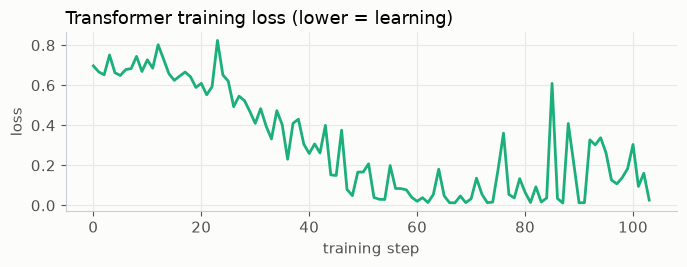

In [7]:
MODEL_NAME = "distilbert-base-multilingual-cased"   # or "xlm-roberta-base", "aubmindlab/bert-base-arabertv02"
EPOCHS, BATCH, LR, MAX_LEN = 4, 16, 5e-5, 64

tf_ready = False
if RUN_TRANSFORMER:
    try:
        import torch
        from transformers import AutoTokenizer, AutoModelForSequenceClassification
        tf_ready = True
    except ImportError:
        print("Skipping the Transformer: run  pip install torch transformers  then restart the kernel.")

if tf_ready:
    torch.manual_seed(SEED)
    device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
    tok = AutoTokenizer.from_pretrained(MODEL_NAME)
    tf_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(device)
    LABEL2ID = {"ham": 0, "spam": 1}

    texts = train_df["text"].tolist()
    labels = torch.tensor([LABEL2ID[l] for l in train_df["label"]])
    opt = torch.optim.AdamW(tf_model.parameters(), lr=LR)
    losses = []
    tf_model.train()
    t0 = time.time()
    for epoch in range(EPOCHS):
        order = np.random.permutation(len(texts))
        for i in range(0, len(texts), BATCH):
            idx = order[i:i + BATCH]
            enc = tok([texts[j] for j in idx], padding=True, truncation=True,
                      max_length=MAX_LEN, return_tensors="pt").to(device)
            loss = tf_model(**enc, labels=labels[idx].to(device)).loss
            loss.backward(); opt.step(); opt.zero_grad()
            losses.append(loss.item())
        print(f"epoch {epoch + 1}/{EPOCHS}  loss {np.mean(losses[-10:]):.3f}  ({time.time() - t0:.0f}s)")
    tf_model.eval()

    fig, ax = plt.subplots(figsize=(7, 2.8))
    ax.plot(losses, color=APPROACH_COLORS["Transformer"], linewidth=2)
    ax.set_title("Transformer training loss (lower = learning)", loc="left")
    ax.set_xlabel("training step"); ax.set_ylabel("loss")
    fig.tight_layout(); fig.savefig(OUT / "transformer_loss.png", dpi=150); plt.show()

In [8]:
if tf_ready:
    @torch.no_grad()
    def tf_spam_prob(texts, bs=32):
        probs = []
        for i in range(0, len(texts), bs):
            enc = tok(texts[i:i + bs], padding=True, truncation=True,
                      max_length=MAX_LEN, return_tensors="pt").to(device)
            probs += torch.softmax(tf_model(**enc).logits, -1)[:, 1].tolist()
        return probs

    def tf_predict(texts):
        return [("spam" if p >= 0.5 else "ham", p) for p in tf_spam_prob(list(texts))]

    def tf_explain(text):
        spans = word_spans(text)
        variants = [text] + [text[:s] + text[e:] for s, e, _ in spans]
        p = tf_spam_prob(variants)
        return [(s, e, p[0] - p[k + 1]) for k, (s, e, _) in enumerate(spans)]

    pred, prob = tf_predict([example])[0]
    display(HTML(page(legend() + side_by_side(example, {"Transformer": {"pred": pred, "prob": prob, "spans": tf_explain(example)}}))))

<div dir="rtl">

## 5. التقنية الرابعة: نموذج لغوي كبير دون تدريب (LLM Zero-shot)

> **موقع هذه التقنية:** تحتاج التقنيتان السابقتان إلى بيانات مصنّفة للتدريب. أما هذه التقنية فتستغني عن هذه البيانات، وتكتفي بوصف المهمة [9].

يُستخدم النموذج كما هو، مع وصف للمهمة بالكلام فقط (Prompt)، فيكون الرد بالتصنيف وبالكلمات المعتمدة في القرار.

هذا يوضح الفرق بين **نموذج مخصص لمهمة واحدة** (التقنيتان 2 و3) و**نموذج عام** يصلح لمهام لغوية كثيرة.

**ملاحظة مهمة حول التلوين:** الكلمات هنا من اختيار النموذج، أي **تفسير ذاتي معلَن من النموذج (Self-reported)**. أما في التقنيتين 2 و3 فتأثير الكلمات مقيس حسابيًا. والفرق بين التفسير المعلَن و"ما يجري داخل النموذج" موضوع مهم في قابلية التفسير (Explainability) [10].

**طريقتان للتشغيل:**
- **Ollama (مجاني ومحلي):** يُثبَّت من ollama.com ثم يُنفَّذ الأمر `ollama pull qwen2.5:7b` (نموذج يدعم العربية جيدًا).
- **DeepSeek API (مدفوع بتكلفة منخفضة):** يُنشأ المفتاح من platform.deepseek.com ويوضع في متغير البيئة `DEEPSEEK_API_KEY`، ثم تُغيَّر قيمة `LLM_BACKEND` إلى `"deepseek"`. ولا يحتاج إلى مكتبة إضافية.

تُحفظ النتائج في `outputs/llm_cache.json` لتوفير الطلبات لاحقًا.

</div>

In [9]:
LLM_BACKEND = "ollama"            # "ollama" or "deepseek"
OLLAMA_MODEL = "qwen2.5:7b"
DEEPSEEK_MODEL = "deepseek-flash"

LLM_PROMPT = """You classify short text messages (SMS / WhatsApp) written in Arabic or English.
Decide if the message is "spam" (scam, phishing, fraud, unwanted promotion) or "ham" (a normal message).
Answer ONLY with JSON in this exact shape:
{"label": "spam" or "ham", "confidence": number between 0 and 1, "evidence": [up to 4 short words or phrases copied exactly from the message that drove your decision]}

Message:
"""

CACHE_PATH = OUT / "llm_cache.json"
llm_cache = json.loads(CACHE_PATH.read_text(encoding="utf-8")) if CACHE_PATH.exists() else {}

def _ask_ollama(text):
    import urllib.request
    body = json.dumps({"model": OLLAMA_MODEL, "stream": False, "format": "json",
                       "options": {"temperature": 0},
                       "messages": [{"role": "user", "content": LLM_PROMPT + text}]}).encode()
    req = urllib.request.Request("http://localhost:11434/api/chat", data=body,
                                 headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=120) as r:
        return json.loads(r.read())["message"]["content"]

def _ask_deepseek(text):
    import urllib.request
    body = json.dumps({"model": DEEPSEEK_MODEL, "max_tokens": 300, "temperature": 0,
                       "thinking": {"type": "disabled"},          # direct answer, no reasoning step
                       "response_format": {"type": "json_object"},
                       "messages": [{"role": "user", "content": LLM_PROMPT + text}]}).encode()
    req = urllib.request.Request("https://api.deepseek.com/chat/completions", data=body,
                                 headers={"Content-Type": "application/json",
                                          "Authorization": f"Bearer {os.environ['DEEPSEEK_API_KEY']}"})
    with urllib.request.urlopen(req, timeout=60) as r:
        return json.loads(r.read())["choices"][0]["message"]["content"]

def llm_classify(text):
    model = OLLAMA_MODEL if LLM_BACKEND == "ollama" else DEEPSEEK_MODEL
    key = f"{LLM_BACKEND}:{model}:{text}"
    if key not in llm_cache:
        raw = _ask_ollama(text) if LLM_BACKEND == "ollama" else _ask_deepseek(text)
        match = re.search(r"\{.*\}", raw, re.S)
        data = json.loads(match.group()) if match else {}
        llm_cache[key] = {
            "label": "spam" if str(data.get("label", "")).lower().startswith("spam") else "ham",
            "confidence": float(data.get("confidence", 0.5)),
            "evidence": [str(e) for e in data.get("evidence", [])][:4],
        }
        CACHE_PATH.write_text(json.dumps(llm_cache, ensure_ascii=False, indent=1), encoding="utf-8")
    return llm_cache[key]

def llm_predict(texts):
    out = []
    for t in texts:
        r = llm_classify(t)
        out.append((r["label"], r["confidence"] if r["label"] == "spam" else 1 - r["confidence"]))
    return out

def llm_explain(text):
    r = llm_classify(text)
    sign = 1 if r["label"] == "spam" else -1
    spans = []
    for ev in r["evidence"]:
        i = text.find(ev)
        if ev and i >= 0:
            spans.append((i, i + len(ev), sign * r["confidence"]))
    return spans

if RUN_LLM and LLM_BACKEND == "ollama" and (IN_COLAB or IN_KAGGLE):
    start_ollama(OLLAMA_MODEL)

llm_ready = False
if RUN_LLM:
    try:
        llm_classify(example)
        llm_ready = True
        pred, prob = llm_predict([example])[0]
        display(HTML(page(legend() + side_by_side(example, {"LLM zero-shot": {"pred": pred, "prob": prob, "spans": llm_explain(example)}}))))
    except Exception as e:
        print(f"Skipping the LLM ({LLM_BACKEND} not reachable): {e}")

<div dir="rtl">

## 6. المقارنة

تُجمع التقنيات الجاهزة في مكان واحد، ثم يُقاس الأداء على مجموعتين:
1. **مجموعة الاختبار العادية:** رسائل من قوالب لم تُستخدم في التدريب، بالأسلوب نفسه.
2. **المجموعة الصعبة:** أساليب تظهر لأول مرة.

**مقاييس الأداء:**
- **الدقة (Accuracy):** نسبة الرسائل المصنّفة تصنيفًا صحيحًا من مجموع الرسائل.
- **الضبط (Precision):** نسبة رسائل الاحتيال الفعلية من بين الرسائل المصنّفة احتيالًا.
- **الاستدعاء (Recall):** نسبة رسائل الاحتيال المكشوفة من مجموع رسائل الاحتيال الفعلية.
- **F1:** متوسط يجمع الضبط والاستدعاء في رقم واحد.

</div>

In [10]:
APPROACHES = {"Traditional": (rules_predict, rules_explain), "Naive Bayes": (nb_predict, nb_explain)}
if tf_ready:
    APPROACHES["Transformer"] = (tf_predict, tf_explain)
if llm_ready:
    APPROACHES["LLM zero-shot"] = (llm_predict, llm_explain)
NAMES = list(APPROACHES)

def evaluate(frame):
    rows, preds = [], {}
    for name, (predict, _) in APPROACHES.items():
        p = [lab for lab, _ in predict(frame["text"].tolist())]
        preds[name] = p
        prec, rec, f1, _ = precision_recall_fscore_support(
            frame["label"], p, pos_label="spam", average="binary", zero_division=0)
        rows.append({"approach": name, "accuracy": accuracy_score(frame["label"], p),
                     "precision": prec, "recall": rec, "f1": f1})
    return pd.DataFrame(rows).set_index("approach"), preds

test_scores, test_preds = evaluate(test_df)
tricky_scores, tricky_preds = evaluate(tricky)

display(HTML("<b>Regular test set</b>")); display(test_scores.style.format("{:.2f}"))
display(HTML("<b>Tricky set</b>")); display(tricky_scores.style.format("{:.2f}"))

,accuracy,precision,recall,f1
approach,,,,
Traditional,0.57,0.55,0.33,0.42
Naive Bayes,0.66,0.68,0.52,0.59
Transformer,0.76,0.83,0.60,0.70
LLM zero-shot,0.84,0.80,0.85,0.83


,accuracy,precision,recall,f1
approach,,,,
Traditional,0.40,0.17,0.05,0.08
Naive Bayes,0.70,0.68,0.75,0.71
Transformer,0.75,0.75,0.75,0.75
LLM zero-shot,0.88,0.89,0.85,0.87


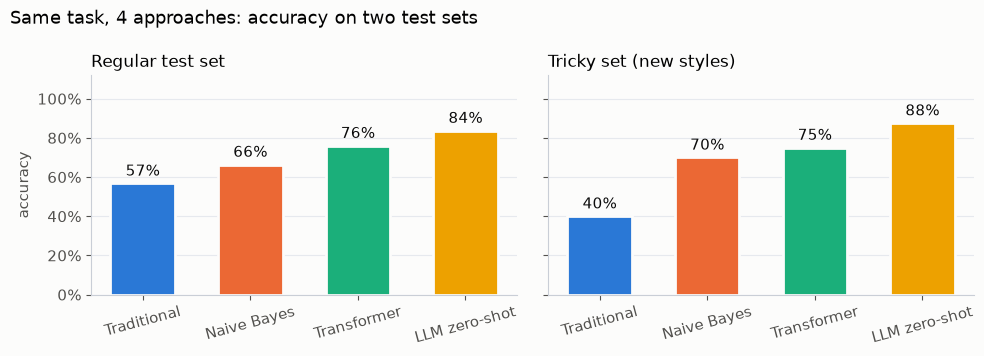

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (title, scores) in zip(axes, [("Regular test set", test_scores), ("Tricky set (new styles)", tricky_scores)]):
    vals = scores["accuracy"]
    bars = ax.bar(NAMES, vals, color=[APPROACH_COLORS[n] for n in NAMES], width=0.6,
                  edgecolor="#fcfcfb", linewidth=2)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in vals], padding=3, color="#0b0b0b")
    ax.set_title(title, loc="left", fontsize=12)
    ax.set_ylim(0, 1.12); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.set_axisbelow(True); ax.grid(axis="x", visible=False); ax.tick_params(axis="x", rotation=15)
axes[0].set_ylabel("accuracy")
fig.suptitle(f"Same task, {len(NAMES)} approaches: accuracy on two test sets", x=0.01, ha="left", fontsize=13)
fig.tight_layout(); fig.savefig(OUT / "accuracy_comparison.png", dpi=150); plt.show()

<div dir="rtl">

**مصفوفة الالتباس (Confusion Matrix):** جدول يعرض عدد الرسائل في كل حالة: الصفوف للتصنيف الصحيح، والأعمدة لتصنيف النموذج. وخانة الرسائل العادية المصنّفة احتيالًا هي "الإنذار الكاذب" الوارد في قسم المشكلة، وخانة رسائل الاحتيال المصنّفة عادية هي "الرسالة الفائتة".

</div>


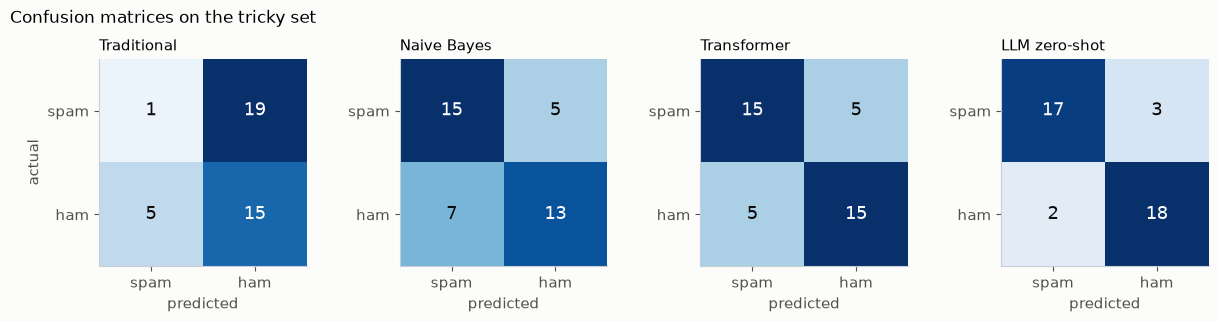

In [12]:
fig, axes = plt.subplots(1, len(NAMES), figsize=(3.1 * len(NAMES), 3.1))
axes = np.atleast_1d(axes)
for ax, name in zip(axes, NAMES):
    cm = confusion_matrix(tricky["label"], tricky_preds[name], labels=["spam", "ham"])
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=max(1, cm.max()))
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center", fontsize=13,
                color="#ffffff" if v > cm.max() / 2 else "#0b0b0b")
    ax.set_xticks([0, 1], ["spam", "ham"]); ax.set_yticks([0, 1], ["spam", "ham"])
    ax.set_xlabel("predicted"); ax.set_title(name, loc="left", fontsize=11)
    ax.grid(False)
axes[0].set_ylabel("actual")
fig.suptitle("Confusion matrices on the tricky set", x=0.01, ha="left", fontsize=12)
fig.tight_layout(); fig.savefig(OUT / "confusion_tricky.png", dpi=150); plt.show()

<div dir="rtl">

### لوحة النتائج: نتيجة كل تقنية في كل رسالة صعبة

</div>

In [13]:
board = [{"text": r.text, "label": r.label, "note": r.why_tricky,
          "preds": {n: tricky_preds[n][i] for n in NAMES}}
         for i, r in enumerate(tricky.itertuples())]
display(HTML(page(scoreboard(board, NAMES))))

Message,Traditional,Naive Bayes,Transformer,LLM zero-shot
ر.ب.ح.ت جائزة كبيرة، كلمني بسرعةspam · تمويه بالنقاط بين الحروف,✓,✓,✓,✓
ق ر ض فوري بدون كفيل، ر ا س ل ن ي الحينspam · تمويه بالمسافات بين الحروف,✗ ham,✓,✓,✓
"mabrook, rbe7t 1000 riyal! ersel ramz el ta2keed 3ashan n7awel lek el mablaghspam · عربيزي بأرقام بدل الحروف",✗ ham,✗ ham,✓,✓
"Salam 5alti, hatha raqmi ljdeed, el 9adeem 5irib. 7awleeli 50 riyal 3ala hal ra9am daroorispam · عربيزي وانتحال قريبة برقم جديد",✗ ham,✗ ham,✗ ham,✗ ham
السلام عليكم، معك موظف البنك، نحتاج الرمز اللي وصلك عشان نوقف العمليةspam · انتحال موظف بنك يطلب الرمز بلا رابط,✗ ham,✓,✗ ham,✓
يا هلا والله، هذي خالتك أم سالم، رقمي الجديد، حوّلي لي 30 ريال ضروريspam · انتحال قريبة برقم جديد وطلب تحويل,✗ ham,✓,✓,✓
عميلنا العزيز، تم إيقاف بطاقتك مؤقتاً. لإعادة التفعيل أدخل بياناتك عبر bank-secure-login.examplespam · نطاق شبيه بنطاق البنك,✗ ham,✓,✓,✓
لديك مبلغ مسترد 45 ر.ع.، امسح الرمز المربع في الصورة المرفقة وأدخل رقم بطاقتك السري لاستلامهspam · احتيال بالرمز المربع بلا رابط,✗ ham,✓,✓,✓
استثمر 100 ريال في العملات الرقمية واربح 3000 خلال أسبوع، أرباح مضمونة، راسلنيspam · استثمار في العملات الرقمية بأرباح مضمونة,✗ ham,✓,✓,✓
مساء الخير أستاذ خالد، موعدنا باقي الليلة؟ 😊spam · افتتاحية رقم خاطئ لاحتيال عاطفي: رسالة ودية لشخص غريب لبدء محادثة,✗ ham,✗ ham,✗ ham,✗ ham


<div dir="rtl">

## 7. المعرض البصري: الكلمات المؤثرة في قرار كل تقنية

تُعرض الرسالة نفسها في أعمدة، يمثل كل عمود تقنية، ويوضح التلوين الكلمات المؤثرة في القرار. ويظهر وزن كل كلمة عند تمرير مؤشر الفأرة فوق الكلمة.

تُحفظ الصفحة كاملة أيضًا في `outputs/gallery.html` للفتح في المتصفح.

</div>

In [14]:
def compare(text, true_label=None, note=None):
    results = {}
    for name, (predict, explain) in APPROACHES.items():
        pred, prob = predict([text])[0]
        results[name] = {"pred": pred, "prob": prob, "spans": explain(text)}
    return side_by_side(text, results, true_label, note)

gallery = legend() + "".join(compare(r.text, r.label, r.why_tricky) for r in tricky.itertuples())
display(HTML(page(gallery)))

_ = (OUT / "gallery.html").write_text(
    '<!doctype html><html><head><meta charset="utf-8"><title>Spam gallery</title></head>'
    f'<body style="margin:24px;background:#eef1f5">{page(gallery)}</body></html>', encoding="utf-8")

<div dir="rtl">

## 8. تجربة رسائل جديدة

يمكن إضافة أي رسالة إلى القائمة أدناه لمعرفة تصنيف التقنيات الأربع.

</div>

In [15]:
my_messages = [
    "هلا، عندك وقت نتكلم عن مشروع الذكاء الاصطناعي؟",
    "Your phone bill is ready, pay now via the app",
    "حبيبتي ارسلي لي الكود اللي وصلك على جوالك ضروري",
]
display(HTML(page(legend() + "".join(compare(m) for m in my_messages))))

In [16]:
# Optional live box (needs: pip install ipywidgets)
try:
    import ipywidgets as widgets
    box = widgets.Textarea(placeholder="نص الرسالة / message text", layout=widgets.Layout(width="100%"))
    btn = widgets.Button(description="Compare")
    out = widgets.Output()
    def on_click(_):
        with out:
            out.clear_output(); display(HTML(page(legend() + compare(box.value))))
    btn.on_click(on_click)
    display(widgets.VBox([box, btn, out]))
except ImportError:
    print("ipywidgets is not installed; use the cell above instead.")

<div dir="rtl">

## 9. الملاحظات وأسئلة التحليل

تُدوَّن الملاحظات هنا بعد التشغيل. وهذه أسئلة تساعد على التحليل والنقاش:

1. **البرمجة التقليدية:** ما الرسائل الصعبة المصنّفة خطأً؟ وهل يعود الخطأ إلى تغيير كتابة الكلمة (ر.ب.ح.ت) أم إلى ورود الكلمة في سياق عادي (مبروك ربحت التحدي)؟
2. **Naive Bayes:** هل ظهرت في التلوين كلمات من خارج قائمة التقنية الأولى؟ وما الكلمات العادية التي نالت وزنًا قويًا بلا سبب منطقي؟ (وجود هذه الكلمات مؤشر على **فرط التخصيص (Overfitting)**: حفظ النموذج تفاصيل بيانات التدريب بدل تعلّم أنماط عامة، فينخفض الأداء على البيانات الجديدة).
3. **Transformer:** هل نجح التصنيف في رسائل الاحتيال الخالية من الروابط والكلمات المشهورة؟ وهل يتوزع التلوين على الجملة بدل التركيز على كلمة واحدة؟
4. **LLM:** ما نتيجة التصنيف أمام أساليب جديدة مثل "Hi mum"؟ وهل الكلمات المقدَّمة دليلًا على القرار منطقية؟
5. **التقييم العام:** متى تكفي البرمجة التقليدية؟ ومتى يستحق التعلم العميق تكلفته؟ ومتى يكون نموذج عام دون تدريب الأنسب؟

</div>

<div dir="rtl">

## 10. ما بعد التجربة: ثغرات تقنيات الكشف الحالية، والذكاء الاصطناعي في الهجوم والدفاع

أظهرت التجربة أن كل تقنية جاءت لمعالجة ثغرة في التقنية السابقة. غير أن الواقع أدق من ذلك: كل تقنية **تعالج ثغرة، ثم تظهر ثغرة جديدة**، والمهاجمون يستخدمون اليوم الأدوات نفسها المستخدمة في الدفاع. ويلخّص هذا القسم ما تذكره المصادر الموثّقة حتى أكتوبر 2026.

> **ملاحظة منهجية:** الأرقام الصادرة عن الشركات عن منتجاتها موسومة بـ **[رقم من المورِّد]**، وما لم يُتحقق منه من مصدره الأصلي موسوم بـ **[مصدر ثانوي]**. ولا يتضمن هذا القسم أي تفاصيل تشغيلية لتنفيذ الهجمات.

### 10.1 ثغرات كل تقنية

تفصّل الفقرات التالية الأسباب الثلاثة الواردة في قسم المشكلة: تغيّر أسلوب المحتال (التصنيف العدائي)، وتغيّر محتوى الرسائل مع الوقت (انجراف المفاهيم)، وصعوبات اللغة العربية.

**البرمجة التقليدية: لا تكشف النص المخفي.** تقوم القواعد على افتراض تطابق النص المحلَّل برمجيًا مع النص الظاهر للإنسان. وقد رصدت Cisco Talos بين عامي 2024 و2025 رسائل تحمل نصًا مخفيًا عن المستلم، مثل المحارف ذات العرض الصفري (Zero-Width Characters) والنصوص المخفية بتنسيقات CSS، بهدف تضليل المرشّحات [11]. كما لا تفيد قواعد فحص الروابط أمام رسالة احتيال بلا رابط.

**تعلّم الآلة: يتأثر بحشو الكلمات وبتسميم بيانات التدريب.** إلى جانب هجوم الكلمات الجيدة [5]، أظهر Nelson وآخرون أن سيطرة المهاجم على نحو **1% من رسائل التدريب** قد تكفي لتعطيل مرشّح بايزي، وهو ما يُعرف بتسميم البيانات (Data Poisoning) [12]. وينتقل هذا الخطر إلى أي نظام يعتمد إعادة التدريب الذاتي على بلاغات المستخدمين. وتواجه هذه التقنية كذلك مشكلة **انجراف المفاهيم (Concept Drift)**: فمجموعة SMS Spam Collection، التي ما زالت شائعة في الدروس، جُمعت عام 2011 [13]، ولا تعكس أساليب اليوم مثل رسائل الطرود والمخالفات المرورية.

**التعلّم العميق: مقاومة أعلى لحشو الكلمات، وتأثر بإعادة الصياغة.** أظهر هجوم TextFooler أن استبدال المرادفات وحده خفّض دقة مصنّفات مثل BERT إلى أقل من 15% مع تغيير أقل من 20% من الكلمات، في مهام تصنيف نصي عامة [14]. ووجد Thapa وآخرون عام 2025 أن إعادة صياغة رسائل التصيّد بنموذج لغوي تُضعف أداء كاشفات تعلّم الآلة والنماذج اللغوية على السواء [15]. فالنموذج المستخدم في كتابة رسالة الاحتيال قادر أيضًا على إعادة صياغة الرسالة إلى حين تجاوز المصنّف.

**النماذج اللغوية الكبيرة: قد تحمل الرسالة المفحوصة تعليمات موجّهة إلى النموذج.** في التقنية الرابعة يأتي نص الرسالة بعد تعليمات المطوّر للنموذج. وهذا يعني اجتماع نص خاضع لتحكم المهاجم مع تعليمات المطوّر في سياق واحد: **حقن التعليمات غير المباشر (Indirect Prompt Injection)**، الخطر الأول في قائمة OWASP لمخاطر تطبيقات النماذج اللغوية لعام 2025 [16]. ولم يعد الأمر نظريًا: ففي عام 2025 جعلت تعليمةٌ مخفية داخل رسالة بريدية مساعدَ Gemini for Workspace يضيف تحذيرًا أمنيًا مزيّفًا إلى ملخص الرسالة [17]، ورُصدت حملة تصيّد حقيقية تحمل نصًا مخفيًا موجّهًا إلى ماسحات البريد التي تستخدم الذكاء الاصطناعي، يطلب من تلك الماسحات اعتبار الرسالة سليمة [18]. يضاف إلى ذلك أن تفسيرات هذه النماذج قد تبدو متسقة ومقنعة رغم ضعف الدقة [19]، مما يؤكد أهمية التفريق المعروض في التقنية الرابعة بين التفسير المقيس والتفسير الذاتي المعلَن من النموذج [10].

**قنوات خارج نطاق المصنّف النصي.** في المحادثات المشفّرة طرفيًا (End-to-End Encryption) يتعذر على الخادم الوصول إلى المحتوى، ولذلك تكافح واتساب الرسائل المزعجة بسلوك الحسابات والبيانات الوصفية (Metadata) لا بنص الرسائل [20]. ورموز QR تحمل الرابط الخبيث صورةً لا نصًا، وقد رصدت تقارير APWG أكثر من 700 ألف رمز QR خبيث فريد في الربع الثالث من 2025 وحده [21]. أما في الاحتيال الحواري، كالاحتيال العاطفي والاستثماري، فتبدأ المحادثة بدردشة عادية بلا رابط ولا كلمة مشبوهة، ولا يظهر الطابع الاحتيالي إلا بعد أيام.

**وتتسع هذه الثغرات في العربية.** تُكتب الكلمة الواحدة بصور كثيرة (أ/إ/ا، ة/ه، ى/ي، مع التشكيل والتطويل)، ولهذا يخضع النص للتطبيع قبل التصنيف. والبحوث العربية في هذا المجال تعتمد غالبًا على بيانات صغيرة وغير متوازنة ومحصورة في لهجات أو مناطق بعينها [22][23]. ولم يُعثر على دراسة منشورة تقيس نجاح التهرّب بالعربيزي (Arabizi) أو التشكيل ضد المصنّفات العربية.

| الثغرة | البرمجة التقليدية | تعلّم الآلة | التعلّم العميق | النموذج اللغوي الكبير |
|---|---|---|---|---|
| النص المخفي | عالية | عالية | متوسطة (حسب التطبيع) | عالية، ويصبح قناة للحقن |
| حشو الكلمات العادية | منخفضة | عالية [5] | أقل | غير مقيسة |
| إعادة الصياغة واستبدال المرادفات | عالية | عالية | عالية [14][15] | متوسطة إلى عالية [15] |
| تسميم بيانات التدريب | لا ينطبق | عالية [12] | قائمة | قائمة عند الضبط الدقيق |
| تنوّع التهجئة العربية | عالية | عالية | متوسطة | غير مقيسة |
| حقن التعليمات | لا ينطبق | لا ينطبق | لا ينطبق | ثغرة بنيوية [16][18] |
| رموز QR والتشفير الطرفي والاحتيال الحواري | خارج النطاق | خارج النطاق | خارج النطاق | جزئيًا (على الجهاز أو متعدد الوسائط) |

*التقديرات في الجدول ("عالية" و"متوسطة") استنتاج تحليلي من الأدلة المذكورة، وليست قياسات موحّدة.*

### 10.2 استخدام المهاجمين للذكاء الاصطناعي

- **رسائل بجودة الخبراء وبكلفة شبه معدومة:** في تجربة لـ IBM عام 2023 كتب الذكاء الاصطناعي رسالة تصيّد مقنعة في نحو 5 دقائق مقابل 16 ساعة لفريق بشري [24]. وفي دراسة مضبوطة عام 2024 بلغت نسبة النقر على رسائل التصيّد الموجَّه المكتوبة آليًا بالكامل **54%**، وهي نسبة الخبراء البشر نفسها، مقابل **12%** للتصيّد العام. والعيّنة صغيرة (101 مشارك) [25].
- **نماذج إجرامية ونماذج عامة يُساء استخدامها:** ظهرت نماذج لغوية مخصصة للجريمة تُباع باشتراكات شهرية، مثل الجيل الرابع من WormGPT عام 2025 [26]. وتفيد تقارير Anthropic وGoogle بأن المحتالين يستخدمون النماذج العامة في الكتابة والترجمة وإدارة المحادثات، وأن حصيلة هذا الاستخدام "مكاسب إنتاجية" أكثر من تطوير قدرات جديدة [27][28].
- **انتهاء علامة "الأخطاء اللغوية":** حذّر مكتب التحقيقات الفيدرالي الأمريكي (FBI) في ديسمبر 2024 من أن الذكاء الاصطناعي يزيل الأخطاء النحوية والإملائية التي كانت تكشف الاحتيال، ويُستخدم في استنساخ الأصوات [29]. ويشير تقرير Europol لعام 2025 إلى تكييف الرسائل مع اللغة والثقافة الخاصتين بالضحية [30].
- **التزييف العميق بعد الرسالة:** في قضية شركة Arup بهونغ كونغ عام 2024 بدأت العملية برسالة أثارت شك الموظف، ثم زال الشك بعد اجتماع فيديو بمشاركين مزيَّفين جميعًا، فحُوِّل نحو 25.6 مليون دولار [31]. ولا يصل المصنّف النصي في هذه العملية إلا إلى الرسالة الأولى.
- **الجودة لا الكمية:** ادّعت شركة SlashNext زيادة رسائل التصيّد بنسبة 1,265% بعد إطلاق ChatGPT **[رقم من المورِّد، ومنهجيته غير منشورة]** [32]، بينما تُظهر أرقام APWG أن إجمالي هجمات التصيّد بقي مستقرًا تقريبًا: نحو 3.8 مليون في 2025 مقابل 3.76 مليون في 2024 [33]. والقراءة الأرجح أن الذكاء الاصطناعي يغيّر **جودة** الرسائل ومستوى التخصيص أكثر من **العدد**.
- **في سلطنة عُمان:** أعلنت شرطة عُمان السلطانية ارتفاع قضايا الاحتيال المالي الإلكتروني بنسبة 50% في النصف الأول من 2025 [34]، وحذّرت من احتيال يستخدم الذكاء الاصطناعي والتزييف العميق لانتحال جهات موثوقة [35]. ولا يوجد حتى الآن قياس منشور لنسبة رسائل الاحتيال العربية المكتوبة بالذكاء الاصطناعي.

### 10.3 استخدام الذكاء الاصطناعي في الدفاع

لا تعتمد المنصات الكبرى على نموذج واحد "أذكى"، بل على **دفاع متعدد الطبقات (Defense in Depth)** يجمع التقنيات الأربع:

- **Gmail:** استبدلت Google عام 2023 طريقة تمثيل النص في مصنّف Gmail بأسلوب RETVec المقاوم للتلاعب بالمحارف، فارتفع الكشف 38% [8]، ثم أضافت عام 2024 نموذجًا لغويًا كبيرًا مخصصًا، مع إعلان حجب 20% رسائل مزعجة أكثر [36] **[رقم من المورِّد]**.
- **Microsoft Defender for Office 365:** تنص الوثائق الرسمية للمنتج على الجمع بين النماذج اللغوية الكبيرة والنماذج اللغوية الصغيرة ونماذج تعلّم الآلة التقليدية في تصنيف التهديدات [37][38].
- **Chrome:** منذ الإصدار 137 عام 2025 يستخرج نموذج Gemini Nano على الجهاز إشارات من محتوى الصفحة، لكن **القرار النهائي يبقى لنظام Safe Browsing** [39].
- **Google Messages:** أضافت Google عام 2024 كشفًا للاحتيال الحواري بنماذج تعمل على الجهاز نفسه احترامًا للخصوصية [40]، وجعلت هذا الكشف مفعّلًا افتراضيًا عام 2025 [41]، ثم أعلنت في أكتوبر 2026 طبقة سحابية اختيارية تفحص المحادثات بنماذج Gemini داخل بيئة حوسبة محمية [42]. والفحص على الجهاز هو الحل العملي لمشكلة التشفير الطرفي، لأن الفحص يجري حيث يُفك التشفير.
- **طبقات لا تقرأ النص أصلًا:** تشترط Gmail وYahoo منذ 2024 على المرسلين بالجملة توثيق الهوية بمعايير SPF وDKIM وDMARC **[مصدر ثانوي]** [43]. وفي الرسائل النصية تعتمد دول الخليج على تسجيل معرّفات المرسلين وقنوات الإبلاغ، مثل الرقم 330330 في السعودية [44].
- **تحصين النموذج اللغوي:** خفّض أسلوب "تسليط الضوء" (Spotlighting) من Microsoft نجاح حقن التعليمات من أكثر من 50% إلى أقل من 2% [45]، لكن هجمات تكيفية رفعت النسبة مجددًا إلى أكثر من 95% [46]. لذلك فالمبدأ التصميمي الأسلم أن يُخرج النموذج اللغوي **تصنيفًا أو درجة فقط، لا ينفّذ أي إجراء**، وأن يُدمج حكم النموذج إشارةً واحدة مع الطبقات الأخرى.
- **هوية الكاتب ليست المعيار:** سحبت OpenAI عام 2023 مصنّف النصوص المولَّدة آليًا بسبب اقتصار الالتقاط على 26% من هذه النصوص، مع 9% إنذارات كاذبة على نصوص بشرية [47]. وتتأثر العلامات المائية مثل SynthID-Text سلبًا بإعادة الصياغة [48]. وكثير من الرسائل المشروعة اليوم مكتوب بمساعدة الذكاء الاصطناعي. لذلك تبحث الأنظمة الحديثة في **نيّة الرسالة وسلوك المرسل**، لا في هوية الكاتب.
- **النموذج الأكبر ليس دائمًا الأفضل:** في المقارنات البحثية تضاهي النماذج الأصغر المضبوطة على المهمة النماذجَ اللغوية الكبيرة أو تتفوق على تلك النماذج، بكلفة أقل بكثير [49][50]، ولهذا تُستدعى النماذج الكبيرة غالبًا للحالات الصعبة فقط.

| الطبقة | ما تعالجه | الحدود |
|---|---|---|
| توثيق هوية المرسل (SPF/DKIM/DMARC، تسجيل معرّفات المرسلين) | انتحال الهوية | لا توقف حسابًا حقيقيًا أُنشئ حديثًا |
| سمعة الروابط والأرقام | المرسلون والروابط المعروفة بالسوء | النطاقات الجديدة والرسائل بلا روابط |
| تطبيع النص وتمثيله بطرق مقاومة للتلاعب | التمويه بالمحارف والنص المخفي | لا تعالج إعادة الصياغة |
| نموذج سريع (تعلّم آلة أو تعلّم عميق) | معظم الرسائل بكلفة منخفضة | التسميم والانجراف والأساليب الجديدة |
| نموذج لغوي كبير يُستدعى عند الحاجة | النيّة والاحتيال الحواري والحالات الملتبسة | الحقن والتحيّز والكلفة |
| بلاغات المستخدمين والتوعية | ما تفوّته جميع الطبقات، وبيانات لإعادة التدريب | قابلة للتسميم وتعتمد على وعي المستخدم |

*ترتيب الطبقات قراءة لما تنشره الشركات عن أنظمة الحماية، فلا تنشر أي شركة تفاصيل التوجيه بين الطبقات.*

### 10.4 الخلاصة

لا يعني تطور التقنيات أن التقنية الرابعة "أفضل" من الأولى، بل يعني أن **كل تقنية عالجت ثغرة ثم ظهرت ثغرة جديدة**: عالج التعلّم العميق الاعتماد على عدّ الكلمات مع بقاء قابلية التأثر بإعادة الصياغة، وعالجت النماذج اللغوية الكبيرة فهم نيّة الرسالة مع قابلية التأثر بحقن التعليمات. ولهذا تجمع الأنظمة الحقيقية بين التقنيات كافة، ولا يُترك القرار النهائي للنموذج اللغوي منفردًا.

وانتهت كذلك قاعدة "الأخطاء اللغوية تعني احتيالًا". فأدوات الذكاء الاصطناعي توفّر للمهاجمين لغة سليمة وتخصيصًا وتنوعًا بكلفة شبه معدومة، ولذلك يعتمد الدفاع على إشارات لا يتحكم فيها كاتب الرسالة: هوية المرسل، وسمعة الرابط، وسلوك الحساب، ومسار المحادثة كاملًا.

وأخيرًا، فإن دقة مرتفعة على بيانات قديمة أو نظيفة لا تعني دقة مماثلة أمام مهاجم حقيقي. والتقييم الجاد يقيس الأداء على بيانات حديثة متنوعة اللهجات وتحت هجوم عدائي.

**مشاريع مقترحة بعد إنهاء الدفتر:**
1. قياس أثر الكتابة بالعربيزي والتشكيل والمحارف المتشابهة على التقنيات الأربع.
2. تجربة حقن تعليمات داخل رسالة ضمن التقنية الرابعة، ثم تطبيق أسلوب "تسليط الضوء" ومقارنة النتائج.
3. بناء نظام طبقي صغير: Naive Bayes للحالات الواضحة، والنموذج اللغوي للحالات ذات الاحتمالات القريبة من 0.5 فقط، ثم مقارنة الدقة والكلفة.
4. إعادة صياغة رسائل المجموعة الصعبة بنموذج لغوي، وقياس تغيّر دقة كل تقنية.

</div>


<div dir="rtl">

## 11. للتوسّع: كتب O'Reilly والأكواد المرافقة على GitHub

تتناول كتب O'Reilly في تعلّم الآلة كشف البريد المزعج مثالًا تعليميًا متكررًا، ويرافق كثيرًا من هذه الكتب مستودعات أكواد رسمية على GitHub قابلة للتشغيل بجانب هذا الدفتر. ويربط الجدول التالي كل كتاب بالتقنية المقابلة:

| الكتاب | الفصل | المحتوى | التقنية | الكود على GitHub |
|---|---|---|---|---|
| Géron، الطبعة الثالثة (2022) [51] | الفصل 1، والفصل 3 (التمرين 4) | الفصل 1: مرشّح البريد المزعج مثالًا على الفرق بين البرمجة التقليدية وتعلّم الآلة. التمرين 4: بناء مصنّف على بيانات SpamAssassin | 1 و2 | `ageron/handson-ml3` ← `03_classification.ipynb` |
| Géron، طبعة PyTorch (2025) [52] | الفصل 1، والفصل 3 | المحتوى نفسه بإطار PyTorch | 1 و2 | `ageron/handson-mlp` ← `03_classification.ipynb` |
| Chio وFreeman (2018) [56] | الفصل 1: Spam Fighting: An Iterative Approach | ثلاث خطوات متتالية: قائمة كلمات محظورة، ثم MinHash LSH، ثم Naive Bayes، على مجموعة TREC 2007 | 1 و2 | `oreilly-mlsec/book-resources` ← `chapter1/` |
| Grus، الطبعة الثانية (2019) [53] | الفصل 13: Naive Bayes | بناء مرشّح بايزي من الصفر بلغة Python دون مكتبات جاهزة | 2 | `joelgrus/data-science-from-scratch` ← `scratch/naive_bayes.py` |
| Conway وWhite (2012) [55] | الفصل 3: Classification: Spam Filtering | مرشّح Naive Bayes بلغة R على بيانات SpamAssassin | 2 | `johnmyleswhite/ML_for_Hackers` ← `03-Classification/email_classify.R` |
| Segaran (2007) [54] | الفصل 6: Document Filtering | المصنّف البايزي وطريقة Fisher لتصفية المستندات والبريد المزعج | 2 | لا يوجد مستودع رسمي |
| Tunstall وآخرون (2022) [58] | الفصلان 2 و9 | ضبط نماذج Transformer للتصنيف، ومقارنة Naive Bayes بالتصنيف دون أمثلة تدريب (Zero-shot) | 3 و4 | `nlp-with-transformers/notebooks` ← `02_classification.ipynb` و`09_few-to-no-labels.ipynb` |
| Alammar وGrootendorst (2024) [57] | الفصل 4: Text Classification | من نموذج مخصص للمهمة إلى التصنيف بالتمثيلات (Embeddings) ثم بالنماذج التوليدية | 3 و4 | `HandsOnLLM/Hands-On-Large-Language-Models` ← `chapter04/` |

**ملاحظات للمتدرب:**
- **أقرب كتاب لمسار هذا الدفتر** هو كتاب Chio وFreeman: البداية قائمة كلمات محظورة، ثم الانتقال إلى تعلّم الآلة خطوة بخطوة. وتُظهر المخرجات المسجّلة في دفاتر المستودع ارتفاع الدقة من 68.6% (القائمة المحظورة) إلى 88.6% (MinHash LSH) ثم 95.6% (Naive Bayes)، ويطابق هذا النمط من التحسّن ما يظهر في هذه التجربة.
- **الحل الرسمي لتمرين Géron** يستخدم الانحدار اللوجستي (Logistic Regression) لا Naive Bayes، ويشير إلى أن تقسيم النص على المسافات يعتمد على اللغة. وهذا ما يجعل تطبيع النص العربي خطوة ضرورية في هذا الدفتر.
- **كتابا Tunstall وAlammar لا يستخدمان بيانات سبام**، بل مراجعات وتصنيفات عامة، غير أن التقنيات المعروضة في الكتابين تنطبق مباشرة على التقنيتين الثالثة والرابعة.
- **ترخيص البيانات:** مجموعة TREC 2007 المستخدمة في كتاب Chio وFreeman تتطلب الموافقة على اتفاقية استخدام قبل تنزيلها.
- **مخطط "قواعد + بيانات ← إجابات" مقابل "بيانات + إجابات ← قواعد"** مصدره كتاب Chollet الصادر عن دار Manning لا O'Reilly [59]، أما مخططات Géron فخاصة بمرشّح البريد المزعج.
- جميع هذه الكتب والأكواد المرافقة بالإنجليزية. وما يضيفه هذا الدفتر تطبيق التقنيات نفسها على رسائل عربية وإنجليزية معًا.

</div>


<div dir="rtl">

## المراجع

</div>

1. Kalat, D. (2018). *Nervous System: Remembering the Dawn of Spam*. BRG. https://www.thinkbrg.com/insights/publications/nervous-system-remembering-the-dawn-of-spam/
2. Sahami, M., Dumais, S., Heckerman, D., & Horvitz, E. (1998). *A Bayesian Approach to Filtering Junk E-Mail*. AAAI-98 Workshop on Learning for Text Categorization. https://www.microsoft.com/en-us/research/publication/a-bayesian-approach-to-filtering-junk-e-mail/
3. The Apache Software Foundation. *Apache SpamAssassin*. https://spamassassin.apache.org/
4. Graham, P. (2002). *A Plan for Spam*. https://www.paulgraham.com/spam.html
5. Lowd, D., & Meek, C. (2005). *Good Word Attacks on Statistical Spam Filters*. Conference on Email and Anti-Spam (CEAS).
6. Vaswani, A., et al. (2017). *Attention Is All You Need*. NeurIPS. https://arxiv.org/abs/1706.03762
7. Devlin, J., et al. (2019). *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding*. NAACL. https://arxiv.org/abs/1810.04805
8. Google Security Blog (2023). *Improving Text Classification Resilience and Efficiency with RETVec*. https://security.googleblog.com/2023/11/improving-text-classification.html
9. Brown, T., et al. (2020). *Language Models are Few-Shot Learners*. NeurIPS. https://arxiv.org/abs/2005.14165
10. Turpin, M., et al. (2023). *Language Models Don't Always Say What They Think: Unfaithful Explanations in Chain-of-Thought Prompting*. NeurIPS. https://arxiv.org/abs/2305.04388
11. Cisco Talos (2025). *Seasoning email threats with hidden text salting*. https://blog.talosintelligence.com/seasoning-email-threats-with-hidden-text-salting/
12. Nelson, B., et al. (2008). *Exploiting Machine Learning to Subvert Your Spam Filter*. USENIX LEET '08. https://www.usenix.org/conference/leet-08/exploiting-machine-learning-subvert-your-spam-filter
13. Almeida, T. A., Gómez Hidalgo, J. M., & Yamakami, A. (2011). *SMS Spam Collection*. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/228/sms+spam+collection
14. Jin, D., Jin, Z., Zhou, J. T., & Szolovits, P. (2020). *Is BERT Really Robust? A Strong Baseline for Natural Language Attack on Text Classification and Entailment*. AAAI. https://arxiv.org/abs/1907.11932
15. Thapa, et al. (2025). *LLMs and ML for phishing email detection, including LLM-rephrased emails*. arXiv:2507.07406. https://arxiv.org/abs/2507.07406
16. OWASP GenAI Security Project (2025). *LLM01:2025 Prompt Injection*. https://genai.owasp.org/llmrisk/llm01-prompt-injection/
17. 0DIN (2025). *Phishing for Gemini*. https://www.0din.ai/blog/phishing-for-gemini
18. Infosecurity Magazine (2025). *Attackers hide AI prompts in phishing emails to target AI-based scanners*. https://infosecurity-magazine.com/news/attackers-hide-ai-prompt
19. Kuikel, Piplai, & Aggarwal (2025). *Evaluating LLMs for phishing detection: accuracy and explanation consistency*. arXiv:2506.13746. https://arxiv.org/abs/2506.13746
20. Jones, M. (2017). *How WhatsApp Reduced Spam while Launching End-to-End Encryption*. USENIX Enigma 2017. https://www.usenix.org/conference/enigma2017/conference-program/presentation/jones
21. APWG (2025). *Phishing Activity Trends Report, Q3 2025*. https://docs.apwg.org/reports/apwg_trends_report_q3_2025.pdf
22. Ibrahim, et al. (2024). *Phishing Detection in Arabic SMS Messages Using Natural Language Processing*. IEEE WiDS-PSU 2024. https://psau.sa.elsevierpure.com/en/publications/phishing-detection-in-arabic-sms-messages-using-natural-language-
23. (2025). *AraSpam: A Multitask Deep Neural Network*. IJACSA 16(8). https://thesai.org/Downloads/Volume16No8/Paper_16-AraSpam_A_Multitask_Deep_Neural_Network.pdf
24. Help Net Security (2023). *Humans vs AI: who writes better phishing emails?* (IBM X-Force). https://www.helpnetsecurity.com/2023/10/26/humans-ai-phishing-emails/
25. Heiding, F., Lermen, S., Kao, A., Schneier, B., & Vishwanath, A. (2024). *Evaluating Large Language Models' Capability to Launch Fully Automated Spear Phishing Campaigns: Validated on Human Subjects*. arXiv:2412.00586. https://arxiv.org/abs/2412.00586
26. BleepingComputer (2025). *Malicious LLMs empower inexperienced hackers with advanced tools* (Palo Alto Networks Unit 42). https://www.bleepingcomputer.com/news/security/malicious-llms-empower-inexperienced-hackers-with-advanced-tools/
27. Anthropic (2025). *Detecting and countering misuse of AI: August 2025*. https://www.anthropic.com/news/detecting-countering-misuse-aug-2025
28. Google Threat Intelligence Group (2025). *Adversarial Misuse of Generative AI*. https://cloud.google.com/blog/topics/threat-intelligence/adversarial-misuse-generative-ai
29. FBI IC3 (2024). *Criminals Use Generative Artificial Intelligence to Facilitate Financial Fraud* (I-120324-PSA). https://www.ic3.gov/PSA/2024/PSA241203
30. eucrim (2025). *Europol IOCTA 2025: Steal, Deal and Repeat*. https://eucrim.eu/news/iocta-2025/
31. CNN (2024). *Arup revealed as victim of $25 million deepfake scam involving Hong Kong employee*. https://edition.cnn.com/2024/05/16/tech/arup-deepfake-scam-loss-hong-kong-intl-hnk
32. NBC Chicago / CNBC (2023). *AI tools such as ChatGPT are generating a mammoth increase in malicious phishing emails* (SlashNext). https://www.nbcchicago.com/news/business/money-report/ai-tools-such-as-chatgpt-are-generating-a-mammoth-increase-in-malicious-phishing-emails/3288905/
33. APWG (2026). *Phishing Activity Trends Report, Q4 2025*. https://docs.apwg.org/reports/apwg_trends_report_q4_2025.pdf
34. Gulf News (2025). *Oman sees 50% surge in cyber financial fraud during first half of 2025*. https://gulfnews.com/world/gulf/oman/oman-sees-50-surge-in-cyber-financial-fraud-during-first-half-of-2025-1.500294444
35. Oman Observer. *Beware of AI-related online scams: ROP*. https://www.omanobserver.om/article/1188082/world/region/beware-of-ai-related-online-scams-rop
36. Google (2024). *Gmail's new defenses against holiday spam and scams*. https://blog.google/products/gmail/gmail-holidays-2024-spam-scam/
37. Microsoft Learn. *Threat classification in Microsoft Defender for Office 365*. https://learn.microsoft.com/en-us/defender-office-365/mdo-threat-classification
38. Microsoft Tech Community (2024). *LLM-powered BEC protection in Microsoft Defender for Office 365*. https://techcommunity.microsoft.com/blog/microsoft365businessblog/-/4303467
39. BleepingComputer (2025). *Google Chrome to use on-device AI to detect tech support scams*. https://www.bleepingcomputer.com/news/security/google-chrome-to-use-on-device-ai-to-detect-tech-support-scams/
40. Google Security Blog (2024). *5 new protections on Google Messages*. https://security.googleblog.com/2024/10/5-new-protections-on-google-messages.html
41. Google (2025). *New AI-powered scam detection features*. https://blog.google/security/new-ai-powered-scam-detection-features/
42. Google (2026). *New Android scam protections*. https://blog.google/security/new-android-scam-protections/
43. Bounteous (2024). *2024 Gmail and Yahoo deliverability changes*. https://www.bounteous.com/insights/2024/01/31/2024-gmail-and-yahoo-deliverability-changes/
44. Arab News. *CITC: fraudulent SMS reports to 330330*. https://arabnews.com/node/1415751/
45. Hines, K., et al. (2024). *Defending Against Indirect Prompt Injection Attacks With Spotlighting*. arXiv:2403.14720. https://arxiv.org/abs/2403.14720
46. (2025). *The Attacker Moves Second: Stronger Adaptive Attacks Bypass Defenses against LLM Jailbreaks and Prompt Injections*. arXiv:2510.09023. https://arxiv.org/abs/2510.09023
47. OpenAI (2023). *New AI classifier for indicating AI-written text* (withdrawn July 2023). https://openai.com/index/new-ai-classifier-for-indicating-ai-written-text
48. Dathathri, S., et al. (2024). *Scalable watermarking for identifying large language model outputs*. Nature 634. https://www.ncbi.nlm.nih.gov/pmc/articles/PMC11499265/
49. (2024). *SecureNet: A Comparative Study of DeBERTa and Large Language Models for Phishing Detection*. arXiv:2406.06663. https://arxiv.org/abs/2406.06663
50. Labonne, M., & Moran, S. (2023). *Spam-T5: Benchmarking Large Language Models for Few-Shot Email Spam Detection*. arXiv:2304.01238. https://arxiv.org/abs/2304.01238
51. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media. Code: https://github.com/ageron/handson-ml3
52. Géron, A. (2025). *Hands-On Machine Learning with Scikit-Learn and PyTorch*. O'Reilly Media. ISBN 979-8-341-60798-9. Code: https://github.com/ageron/handson-mlp
53. Grus, J. (2019). *Data Science from Scratch* (2nd ed.). O'Reilly Media. ISBN 978-1-492-04113-9. Code: https://github.com/joelgrus/data-science-from-scratch
54. Segaran, T. (2007). *Programming Collective Intelligence*. O'Reilly Media. ISBN 978-0-596-52932-1.
55. Conway, D., & White, J. M. (2012). *Machine Learning for Hackers*. O'Reilly Media. Code: https://github.com/johnmyleswhite/ML_for_Hackers
56. Chio, C., & Freeman, D. (2018). *Machine Learning and Security*. O'Reilly Media. ISBN 978-1-491-97990-7. Code: https://github.com/oreilly-mlsec/book-resources
57. Alammar, J., & Grootendorst, M. (2024). *Hands-On Large Language Models*. O'Reilly Media. Code: https://github.com/HandsOnLLM/Hands-On-Large-Language-Models
58. Tunstall, L., von Werra, L., & Wolf, T. (2022). *Natural Language Processing with Transformers* (revised ed.). O'Reilly Media. Code: https://github.com/nlp-with-transformers/notebooks
59. Chollet, F. (2021). *Deep Learning with Python* (2nd ed.). Manning Publications. Chapter 1.
60. Fawcett, T. (2003). *"In vivo" spam filtering: A challenge problem for KDD*. SIGKDD Explorations, 5(2), 140–148. https://arxiv.org/abs/cs/0405007
61. Dalvi, N., Domingos, P., Mausam, Sanghai, S., & Verma, D. (2004). *Adversarial Classification*. KDD '04, 99–108. https://homes.cs.washington.edu/~pedrod/papers/kdd04.pdf
62. Pu, C., & Webb, S. (2006). *Observed Trends in Spam Construction Techniques: A Case Study of Spam Evolution*. CEAS 2006, 104–112. https://sites.cc.gatech.edu/projects/doi/Papers/Pu_CEAS_2006.pdf
63. Kumaran, N. (2019). *Spam does not bring us joy: ridding Gmail of 100 million more spam messages with TensorFlow*. Google Workspace Blog. https://workspace.google.com/blog/product-announcements/ridding-gmail-of-100-million-more-spam-messages-with-tensorflow
